#Taller 2

#1.  Protocolo EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import utilidades
import warnings
warnings.filterwarnings('ignore')

df=pd.read_excel("eppec_prd_petroleo_acumulada_2026.xlsx")
df.head()#muestra de las 5 primeras filas del DF

,AÑO,MES,ACTIVO,CRUDO,GAS
0,2022,1,AM,1553.440,768993.480
1,2022,1,AP,111303.525,10983.318
2,2022,1,AU,2201299.520,284893.113
3,2022,1,CU,743335.360,156702.520
4,2022,1,EY,829270.640,117907.832


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Paso 1 · La pregunta
| Pregunta | Tipo de variables | Prueba |
|---|---|---|
| ¿Existe relación entre la producción de crudo y gas? | 1 numérica | Pearson / Spearman |

#Paso 2 · Estructura

In [2]:
df.shape #describe el las dimensiones de DF

df.dtypes#describe los tipos de datos

df.info()#informacion completad del tipo de columna, vallores y tipos de datos

#Univariado: cada variable por sí sola.#
df.describe()#estadistica descritiva del DF

<class 'pandas.DataFrame'>
RangeIndex: 802 entries, 0 to 801
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AÑO     802 non-null    int64  
 1   MES     802 non-null    int64  
 2   ACTIVO  802 non-null    str    
 3   CRUDO   802 non-null    float64
 4   GAS     802 non-null    float64
dtypes: float64(2), int64(2), str(1)
memory usage: 31.5 KB


,AÑO,MES,CRUDO,GAS
count,802.000000,802.000000,8.020000e+02,802.000000
mean,2023.887781,6.213217,8.026312e+05,239749.285963
std,1.364752,3.357690,7.386164e+05,217471.264774
min,2022.000000,1.000000,9.444000e+01,0.000000
25%,2023.000000,3.000000,3.000267e+05,76062.094500
50%,2024.000000,6.000000,4.745542e+05,166751.078500
75%,2025.000000,9.000000,1.376390e+06,310219.257500
max,2026.000000,12.000000,2.456959e+06,842315.040000


PASO 2.1: Busqueda de valores nulos

In [3]:
#Prueba 2
df_n=utilidades.reporte_nulos(df)
df_n.head(20)

,columna,nulos,porcentaje_nulos
0,AÑO,0,0.0
1,MES,0,0.0
2,ACTIVO,0,0.0
3,CRUDO,0,0.0
4,GAS,0,0.0


PASO 2.2: Merge con los metadatos de precios y nomenclatura de activos

In [4]:
df_a=pd.read_csv("activos_nomenclatura.csv",delimiter=',')
df_a.head()

,Activo,Nomenclatura
0,Amo-Iro-Tivacuno,AIT
1,Amistad,AM
2,Apaika,AP
3,Auca,AU
4,Amazonia Viva,AV


In [5]:
df_merged=pd.merge(df,df_a,left_on='ACTIVO',right_on='Nomenclatura',how='left')
df_merged=df_merged.drop(columns=['Nomenclatura'])
df_merged.head()

,AÑO,MES,ACTIVO,CRUDO,GAS,Activo
0,2022,1,AM,1553.440,768993.480,Amistad
1,2022,1,AP,111303.525,10983.318,Apaika
2,2022,1,AU,2201299.520,284893.113,Auca
3,2022,1,CU,743335.360,156702.520,Cuyabeno
4,2022,1,EY,829270.640,117907.832,Edén Yuturi


In [6]:
df_merged['AÑO']=df_merged['AÑO'].astype('str')
df_merged['MES']=df_merged['MES'].astype('str')
df_merged['fecha_completa']=pd.concat([df_merged['AÑO'],df_merged['MES']], axis=1).agg('-'.join, axis=1)
df_merged['fecha_completa'] = pd.to_datetime(df_merged['fecha_completa'], format='%Y-%m')
df_merged['fecha_completa'] = df_merged['fecha_completa'].dt.strftime('%Y-%m-%d')
df_merged.head()

,AÑO,MES,ACTIVO,CRUDO,GAS,Activo,fecha_completa
0,2022,1,AM,1553.440,768993.480,Amistad,2022-01-01
1,2022,1,AP,111303.525,10983.318,Apaika,2022-01-01
2,2022,1,AU,2201299.520,284893.113,Auca,2022-01-01
3,2022,1,CU,743335.360,156702.520,Cuyabeno,2022-01-01
4,2022,1,EY,829270.640,117907.832,Edén Yuturi,2022-01-01


In [7]:
df_f=pd.read_csv("precio-petrleo-crudo-ecu.csv",delimiter=',')
df_f.head()
df_f['Período']=pd.to_datetime(df_f['Período'])
df_f.head()

,Período,Precio Petróleo Crudo Ecuatoriano en USD por Barril
0,2021-01-01,48.60
1,2021-02-01,55.61
2,2021-03-01,58.72
3,2021-04-01,57.24
4,2021-05-01,61.52


In [8]:
df_merged['fecha_completa'] = pd.to_datetime(df_merged['fecha_completa'])
df_merged_1=pd.merge(df_merged,df_f,left_on='fecha_completa',right_on='Período',how='left')
df_merged_1=df_merged_1.drop(columns=['Período'])
df_merged_1.head()

,AÑO,MES,ACTIVO,CRUDO,GAS,Activo,fecha_completa,Precio Petróleo Crudo Ecuatoriano en USD por Barril
0,2022,1,AM,1553.440,768993.480,Amistad,2022-01-01,77.62
1,2022,1,AP,111303.525,10983.318,Apaika,2022-01-01,77.62
2,2022,1,AU,2201299.520,284893.113,Auca,2022-01-01,77.62
3,2022,1,CU,743335.360,156702.520,Cuyabeno,2022-01-01,77.62
4,2022,1,EY,829270.640,117907.832,Edén Yuturi,2022-01-01,77.62


PASO 2.3: Estandarización de los nombre de las columnas

In [9]:
df_merged_1=utilidades.limpiar_nombres_columnas(df_merged_1)
df_merged_1.head()

,ano,mes,activo,crudo,gas,activo,fecha_completa,precio_petroleo_crudo_ecuatoriano_en_usd_por_barril
0,2022,1,AM,1553.440,768993.480,Amistad,2022-01-01,77.62
1,2022,1,AP,111303.525,10983.318,Apaika,2022-01-01,77.62
2,2022,1,AU,2201299.520,284893.113,Auca,2022-01-01,77.62
3,2022,1,CU,743335.360,156702.520,Cuyabeno,2022-01-01,77.62
4,2022,1,EY,829270.640,117907.832,Edén Yuturi,2022-01-01,77.62


In [10]:
df_merged_1.columns=['anio','mes', 'activo','produccion_crudo', 'produccion_gas','nombre_activo','fecha_completa','precio_mensual_barril_crudo']
df_merged_1.head()

,anio,mes,activo,produccion_crudo,produccion_gas,nombre_activo,fecha_completa,precio_mensual_barril_crudo
0,2022,1,AM,1553.440,768993.480,Amistad,2022-01-01,77.62
1,2022,1,AP,111303.525,10983.318,Apaika,2022-01-01,77.62
2,2022,1,AU,2201299.520,284893.113,Auca,2022-01-01,77.62
3,2022,1,CU,743335.360,156702.520,Cuyabeno,2022-01-01,77.62
4,2022,1,EY,829270.640,117907.832,Edén Yuturi,2022-01-01,77.62


In [12]:
# Exportar a CSV
ruta_drive = ""
df_merged_1.to_csv("datos_produccion_petrolera_limpia.csv", index=False)
print("datos de producción petrolera limpia y actualizada")

datos de producción petrolera limpia y actualizada


PASO 2.4: Conversionn de mes, activo y nombre de activo a categoria a categoria

In [35]:
df_merged_1['mes']=df_merged_1['mes'].astype('category')
df_merged_1['activo']=df_merged_1['activo'].astype('category')
df_merged_1['nombre_activo']=df_merged_1['nombre_activo'].astype('category')
df_merged_1.info()
df_merged_1.head()

<class 'pandas.DataFrame'>
Index: 793 entries, 0 to 801
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   anio                         793 non-null    str           
 1   mes                          793 non-null    category      
 2   activo                       793 non-null    category      
 3   produccion_crudo             793 non-null    float64       
 4   produccion_gas               793 non-null    float64       
 5   nombre_activo                757 non-null    category      
 6   fecha_completa               793 non-null    datetime64[us]
 7   precio_mensual_barril_crudo  793 non-null    float64       
dtypes: category(3), datetime64[us](1), float64(3), str(1)
memory usage: 39.8 KB


,anio,mes,activo,produccion_crudo,produccion_gas,nombre_activo,fecha_completa,precio_mensual_barril_crudo
0,2022,1,AM,1553.440,768993.480,Amistad,2022-01-01,77.62
1,2022,1,AP,111303.525,10983.318,Apaika,2022-01-01,77.62
2,2022,1,AU,2201299.520,284893.113,Auca,2022-01-01,77.62
3,2022,1,CU,743335.360,156702.520,Cuyabeno,2022-01-01,77.62
4,2022,1,EY,829270.640,117907.832,Edén Yuturi,2022-01-01,77.62


In [14]:
df_n=utilidades.reporte_nulos(df_merged_1)
df_n.head(20)

,columna,nulos,porcentaje_nulos
0,nombre_activo,36,4.488778
1,precio_mensual_barril_crudo,15,1.870324
2,anio,0,0.000000
3,mes,0,0.000000
4,produccion_crudo,0,0.000000
5,activo,0,0.000000
6,produccion_gas,0,0.000000
7,fecha_completa,0,0.000000


In [15]:
df_11=df_merged_1[df_merged_1['precio_mensual_barril_crudo'].isnull()]
df_11.head(30)

,anio,mes,activo,produccion_crudo,produccion_gas,nombre_activo,fecha_completa,precio_mensual_barril_crudo
787,2026,8,AIT,348145.510,96110.090,Amo-Iro-Tivacuno,2026-08-01,NaN
788,2026,8,AM,821.060,766644.590,Amistad,2026-08-01,NaN
789,2026,8,AP,222577.648,22605.305,Apaika,2026-08-01,NaN
790,2026,8,AU,1983704.650,255774.196,Auca,2026-08-01,NaN
791,2026,8,AV,1020.160,0.000,Amazonia Viva,2026-08-01,NaN
792,2026,8,CU,549021.250,134809.827,Cuyabeno,2026-08-01,NaN
793,2026,8,EY,834881.133,152185.175,Edén Yuturi,2026-08-01,NaN
794,2026,8,IN,403581.180,64349.000,Indillana,2026-08-01,NaN
795,2026,8,ITT,1242631.489,62307.028,Ishpingo-Tiputini-Tambococha,2026-08-01,NaN
796,2026,8,LA,451687.660,210063.099,Lago Agrio,2026-08-01,NaN


In [16]:
media = df_merged_1[df_merged_1['anio'] == '2026']['precio_mensual_barril_crudo'].mean()
df_merged_1['precio_mensual_barril_crudo']=df_merged_1['precio_mensual_barril_crudo'].fillna(media)
df_n=utilidades.reporte_nulos(df_merged_1)
df_n.head(20)

,columna,nulos,porcentaje_nulos
0,nombre_activo,36,4.488778
1,anio,0,0.000000
2,activo,0,0.000000
3,mes,0,0.000000
4,produccion_crudo,0,0.000000
5,produccion_gas,0,0.000000
6,fecha_completa,0,0.000000
7,precio_mensual_barril_crudo,0,0.000000


#Paso 3 univariado

In [22]:
print(f"Mediana de la cantidad de crudo: {df_merged_1['produccion_crudo'].median():.2f}")
print(f"Media de la cantidad de crudo: {df_merged_1['produccion_crudo'].mean():.2f}")
print(f"Asimetría de la cantidad de crudo: {df_merged_1['produccion_crudo'].skew():.2f}")
print("Desviacion estandar:\n", df_merged_1['produccion_crudo'].std())
print(f"Mediana de la cantidad de gas: {df_merged_1['produccion_gas'].median():.2f}")
print(f"Media de la cantidad de gas: {df_merged_1['produccion_gas'].mean():.2f}")
print(f"Asimetría de la cantidad de gas: {df_merged_1['produccion_gas'].skew():.2f}")
print("Desviacion estandar:\n", df_merged_1['produccion_gas'].std())
print(f"Mediana de la cantidad de gas: {df_merged_1['precio_mensual_barril_crudo'].median():.2f}")
print(f"Media de la cantidad de gas: {df_merged_1['precio_mensual_barril_crudo'].mean():.2f}")
print(f"Asimetría de la cantidad de gas: {df_merged_1['precio_mensual_barril_crudo'].skew():.2f}")
print("Desviacion estandar:\n", df_merged_1['precio_mensual_barril_crudo'].std())

Mediana de la cantidad de crudo: 474554.16
Media de la cantidad de crudo: 802631.24
Asimetría de la cantidad de crudo: 0.90
Desviacion estandar:
 738616.4242658697
Mediana de la cantidad de gas: 166751.08
Media de la cantidad de gas: 239749.29
Asimetría de la cantidad de gas: 1.03
Desviacion estandar:
 217471.26477383697
Mediana de la cantidad de gas: 68.72
Media de la cantidad de gas: 71.02
Asimetría de la cantidad de gas: 0.70
Desviacion estandar:
 12.69965733782359


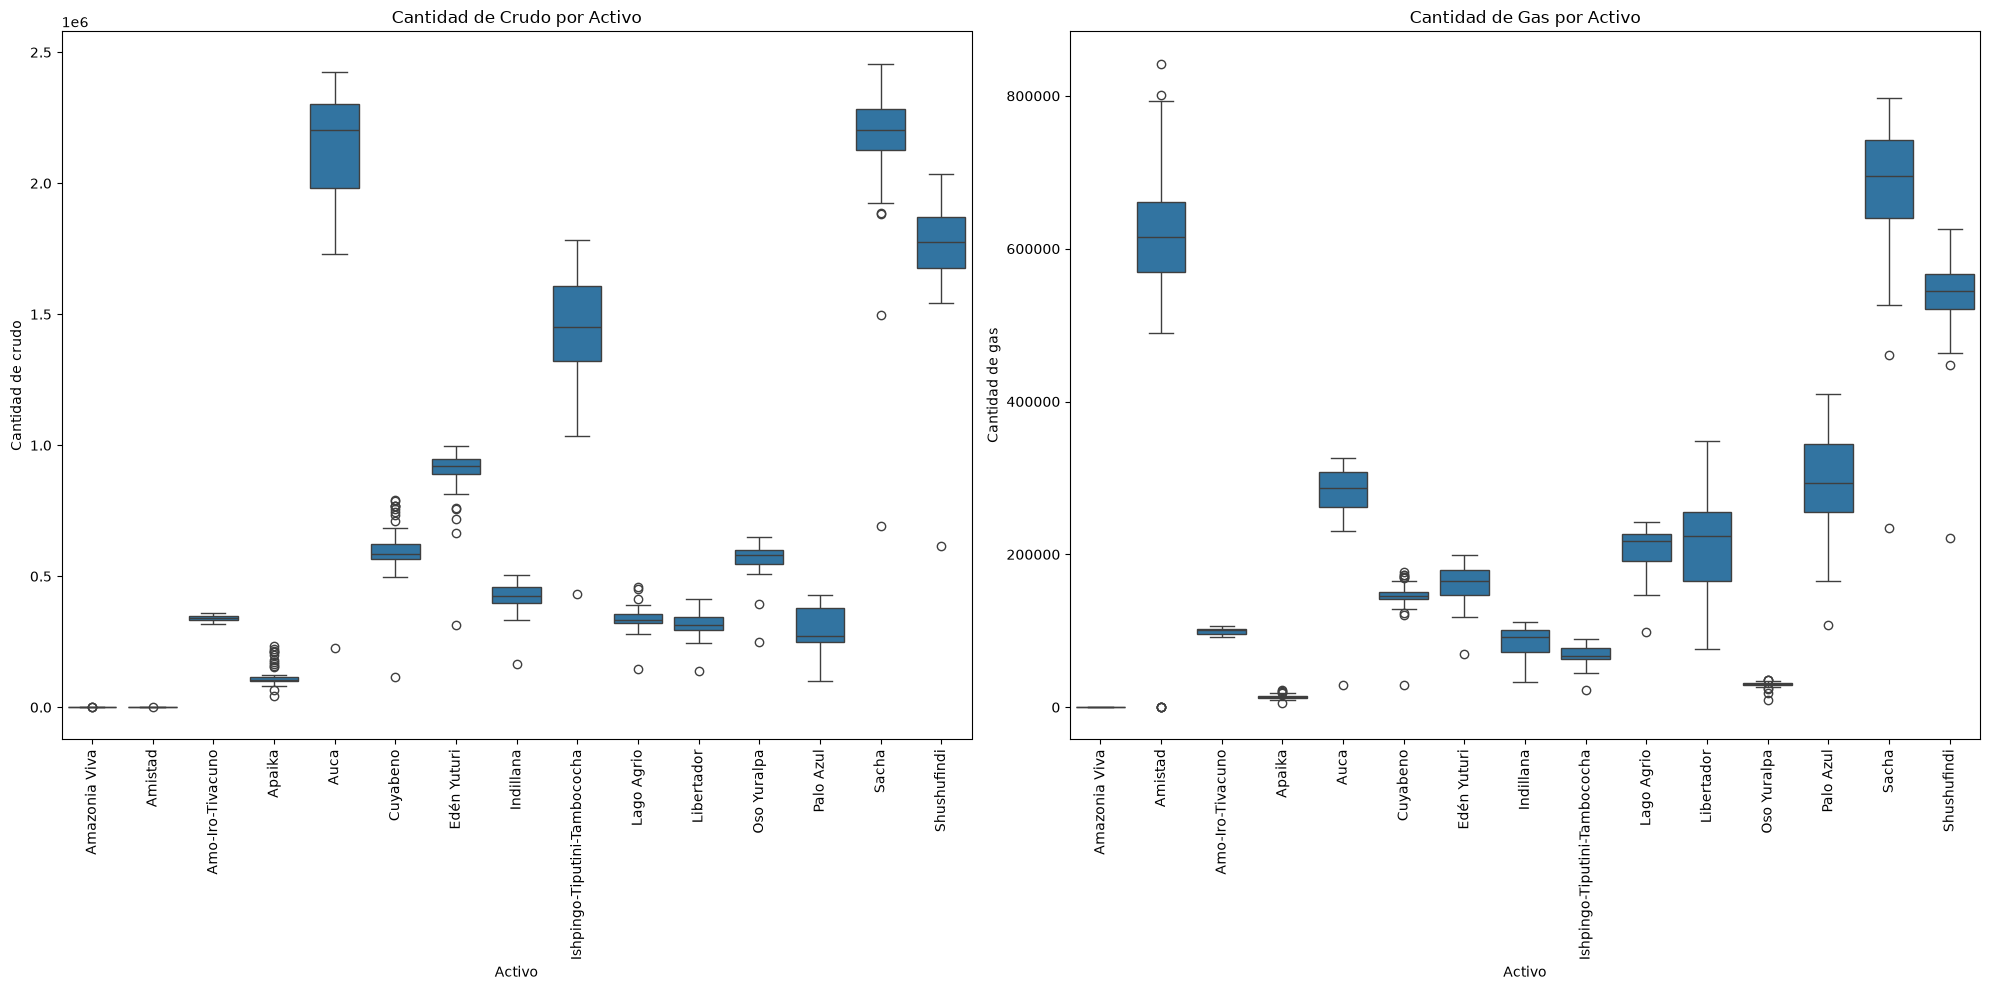

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
sns.boxplot(x='nombre_activo', y='produccion_crudo',ax=axes[0], data=df_merged_1)
axes[0].set_title('Cantidad de Crudo por Activo')
axes[0].set_xlabel('Activo')
axes[0].set_ylabel('Cantidad de crudo')
axes[0].tick_params(axis='x', rotation=90)

sns.boxplot(x='nombre_activo', y='produccion_gas',ax=axes[1], data=df_merged_1)
axes[1].set_title('Cantidad de Gas por Activo') # Corrected title for gas plot
axes[1].set_xlabel('Activo')
axes[1].set_ylabel('Cantidad de gas')
axes[1].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

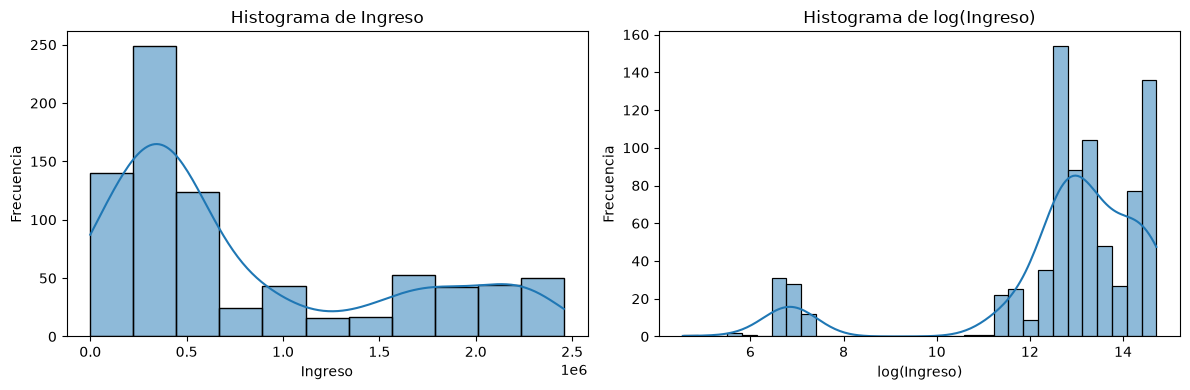

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Histograma del ingreso original
sns.histplot(df_merged_1['produccion_crudo'].dropna(), kde=True, ax=ax[0])
ax[0].set_title('Histograma de Ingreso')
ax[0].set_xlabel('Ingreso')
ax[0].set_ylabel('Frecuencia')

# Histograma del logaritmo del ingreso
sns.histplot(np.log(df_merged_1['produccion_crudo'].dropna()), kde=True, ax=ax[1])
ax[1].set_title('Histograma de log(Ingreso)')
ax[1].set_xlabel('log(Ingreso)')
ax[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

#Paso 4: Bivariado

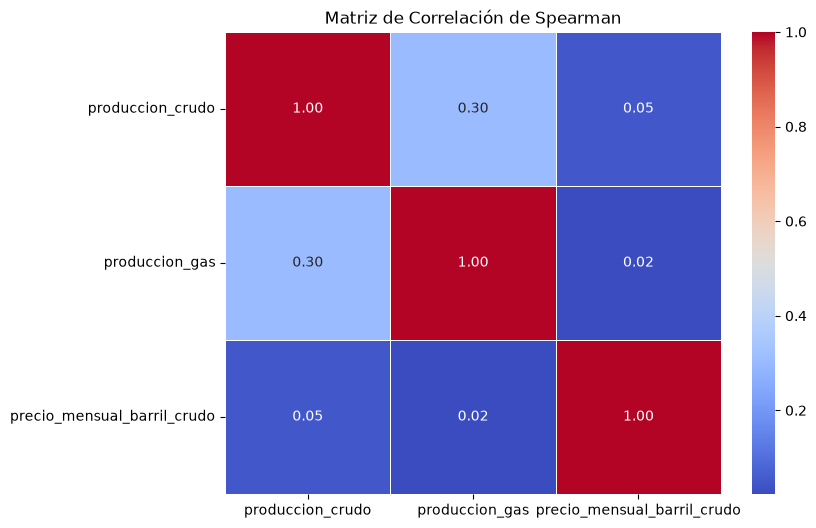

In [26]:
selected_cols = ['produccion_crudo', 'produccion_gas', 'precio_mensual_barril_crudo']
correlation_matrix = df_merged_1[selected_cols].corr(method='spearman')
#Generamos el mapa de calor solicitado entre las variables
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Spearman')
plt.show()

## Paso 5 · Faltantes, duplicados y atípicos

PASO 5.1: Nulos

In [27]:
#Faltantes
media = df_merged_1[df_merged_1['anio'] == '2026']['precio_mensual_barril_crudo'].mean()
df_merged_1['precio_mensual_barril_crudo']=df_merged_1['precio_mensual_barril_crudo'].fillna(media)
df_n=utilidades.reporte_nulos(df_merged_1)
df_n.head(20)

,columna,nulos,porcentaje_nulos
0,nombre_activo,36,4.488778
1,anio,0,0.000000
2,activo,0,0.000000
3,mes,0,0.000000
4,produccion_crudo,0,0.000000
5,produccion_gas,0,0.000000
6,fecha_completa,0,0.000000
7,precio_mensual_barril_crudo,0,0.000000


PASO 5.2: Duplicados

In [ ]:
duplicated_rows = df_merged_1[df_merged_1.duplicated()]
if not duplicated_rows.empty:
    print(f"Se encontraron {len(duplicated_rows)} filas duplicadas:")
    display(duplicated_rows)
else:
    print("No se encontraron filas duplicadas.")


Se encontraron 9 filas duplicadas:


,anio,mes,activo,produccion_crudo,produccion_gas,nombre_activo,fecha_completa,precio_mensual_barril_crudo
104,2022,8,AP,109785.831,14019.320,Apaika,2022-08-01,83.28
105,2022,8,EY,952832.426,152400.210,Edén Yuturi,2022-08-01,83.28
106,2022,8,IN,483442.900,94161.000,Indillana,2022-08-01,83.28
107,2022,8,ITT,1600149.413,67250.136,Ishpingo-Tiputini-Tambococha,2022-08-01,83.28
111,2022,8,LI,349643.790,231162.511,Libertador,2022-08-01,83.28
112,2022,8,SH,1989905.450,625476.445,Shushufindi,2022-08-01,83.28
114,2022,8,OY,590887.110,30891.720,Oso Yuralpa,2022-08-01,83.28
115,2022,8,PA,271205.650,233574.355,Palo Azul,2022-08-01,83.28
116,2022,8,SA,2159797.640,658193.058,Sacha,2022-08-01,83.28


In [29]:
df_merged_1.drop_duplicates(inplace=True)
print(f"El DataFrame ahora tiene {df_merged_1.shape[0]} filas y {df_merged_1.shape[1]} columnas después de eliminar duplicados.")

El DataFrame ahora tiene 793 filas y 8 columnas después de eliminar duplicados.


PASO 5.3: Atipicos

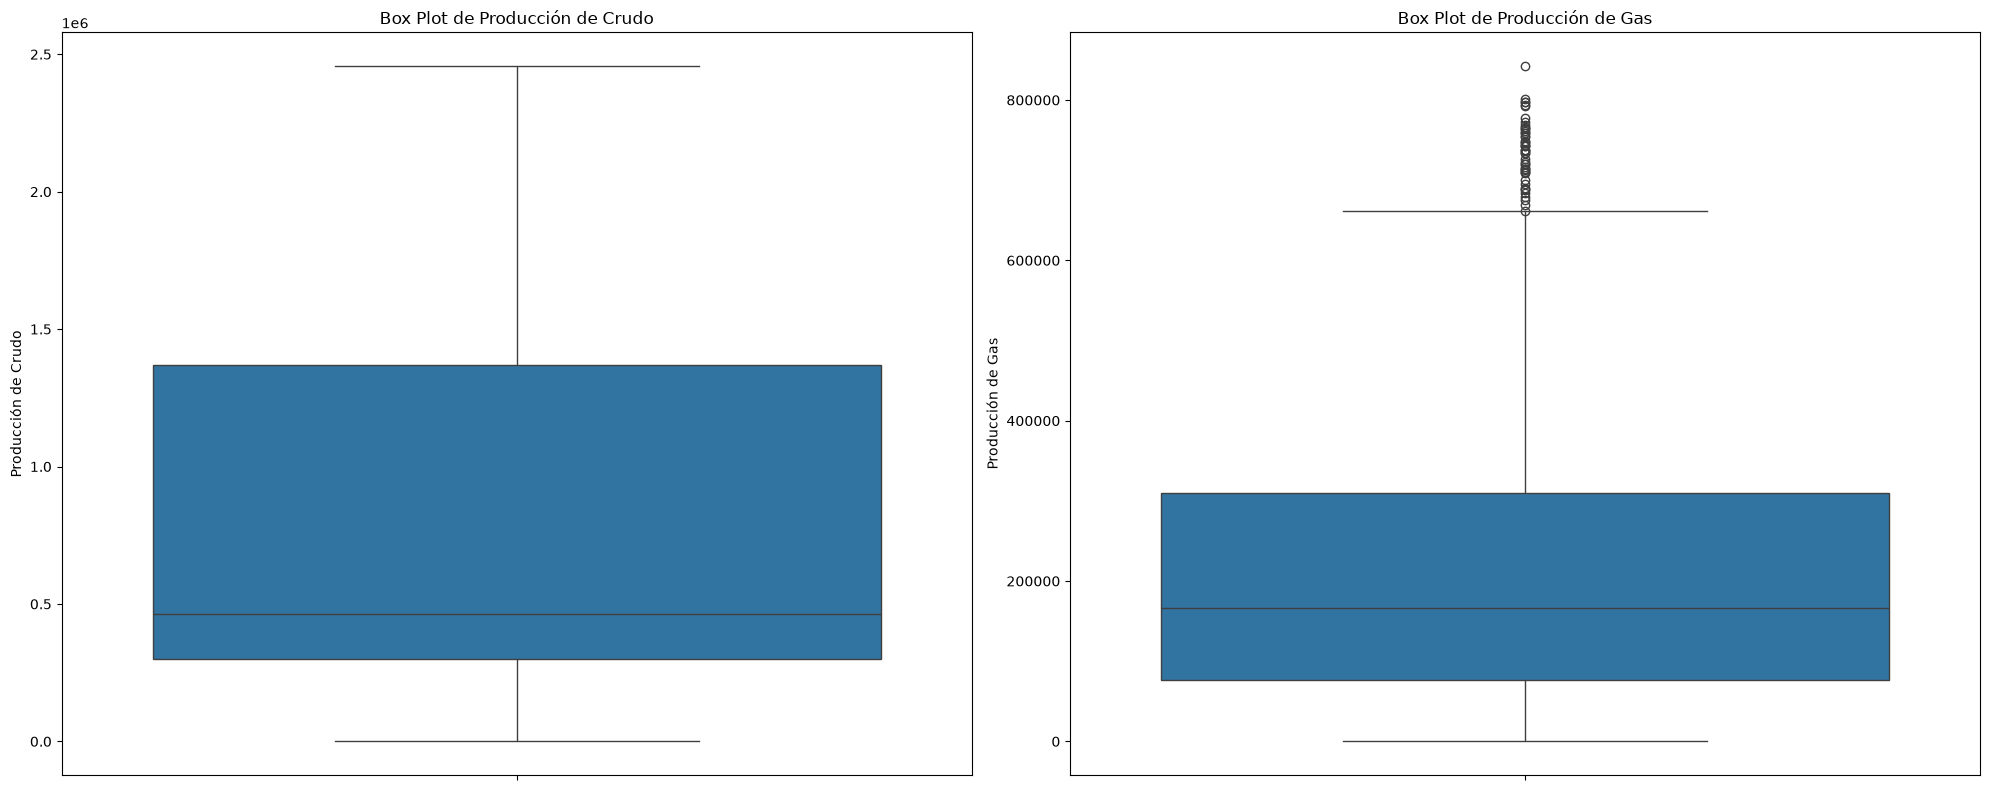

Valores atípicos para Producción de Crudo (basado en IQR):
Se encontraron 0 valores atípicos en Producción de Crudo.

Valores atípicos para Producción de Gas (basado en IQR):
Se encontraron 49 valores atípicos en Producción de Gas.


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.boxplot(y=df_merged_1['produccion_crudo'], ax=axes[0])
axes[0].set_title('Box Plot de Producción de Crudo')
axes[0].set_ylabel('Producción de Crudo')

sns.boxplot(y=df_merged_1['produccion_gas'], ax=axes[1])
axes[1].set_title('Box Plot de Producción de Gas')
axes[1].set_ylabel('Producción de Gas')

plt.tight_layout()
plt.show()

print("Valores atípicos para Producción de Crudo (basado en IQR):")
Q1_crudo = df_merged_1['produccion_crudo'].quantile(0.25)
Q3_crudo = df_merged_1['produccion_crudo'].quantile(0.75)
IQR_crudo = Q3_crudo - Q1_crudo
outlier_crudo_upper = Q3_crudo + 1.5 * IQR_crudo
outlier_crudo_lower = Q1_crudo - 1.5 * IQR_crudo
outliers_crudo = df_merged_1[(df_merged_1['produccion_crudo'] < outlier_crudo_lower) | (df_merged_1['produccion_crudo'] > outlier_crudo_upper)]
print(f"Se encontraron {len(outliers_crudo)} valores atípicos en Producción de Crudo.")
# display(outliers_crudo.head())

print("\nValores atípicos para Producción de Gas (basado en IQR):")
Q1_gas = df_merged_1['produccion_gas'].quantile(0.25)
Q3_gas = df_merged_1['produccion_gas'].quantile(0.75)
IQR_gas = Q3_gas - Q1_gas
outlier_gas_upper = Q3_gas + 1.5 * IQR_gas
outlier_gas_lower = Q1_gas - 1.5 * IQR_gas
outliers_gas = df_merged_1[(df_merged_1['produccion_gas'] < outlier_gas_lower) | (df_merged_1['produccion_gas'] > outlier_gas_upper)]
print(f"Se encontraron {len(outliers_gas)} valores atípicos en Producción de Gas.")
# display(outliers_gas.head())

**Justificación:**
Corresponden a personal reales a la producción de gas de los activos mas grandes.

## Paso 6 · Segmentación: Comparativa de la mediana de Crudo y Gas por Activo

In [32]:
pivot_median = df_merged_1.pivot_table(index='nombre_activo', values=['produccion_crudo', 'produccion_gas'], aggfunc='median')
display(pivot_median)

,produccion_crudo,produccion_gas
nombre_activo,,
Amazonia Viva,8.027700e+02,0.0000
Amistad,9.708900e+02,615823.4200
Amo-Iro-Tivacuno,3.415723e+05,101224.7000
Apaika,1.046397e+05,13856.0710
Auca,2.202917e+06,286915.6650
Cuyabeno,5.864125e+05,145221.4540
Edén Yuturi,9.209964e+05,165846.8120
Indillana,4.232352e+05,92208.0000
Ishpingo-Tiputini-Tambococha,1.438207e+06,67756.3100


## Paso 7 · Justificación

#2.Prueba estadistica a la pregunta

In [33]:
from scipy import stats
# Eliminar filas con valores NaN en las columnas relevantes para la correlación
df_corr = df_merged_1.dropna(subset=['produccion_crudo', 'produccion_gas']).copy()

# Correlación de Pearson
pearson_corr, pearson_p_value = stats.pearsonr(df_corr['produccion_crudo'], df_corr['produccion_gas'])
print(f"--- Correlación de Pearson ---")
print(f"Coeficiente de Pearson: {pearson_corr:,.2f}")
print(f"Valor p (Pearson): {pearson_p_value:,.4f}")

# Correlación de Spearman
spearman_corr, spearman_p_value = stats.spearmanr(df_corr['produccion_crudo'], df_corr['produccion_gas'])
print(f"\n--- Correlación de Spearman ---")
print(f"Coeficiente de Spearman: {spearman_corr:,.2f}")
print(f"Valor p (Spearman): {spearman_p_value:,.4f}")

--- Correlación de Pearson ---
Coeficiente de Pearson: 0.44
Valor p (Pearson): 0.0000

--- Correlación de Spearman ---
Coeficiente de Spearman: 0.30
Valor p (Spearman): 0.0000


##Respuesta:
Existe una correlacion media positiva entre las variables producción de crudo y producción de gas, adicional se evidencia una discrepancia entre el coeficiente de Pearson (0.44) y Spearman (0.3), debido a que esta relacion debe ser monotónica pero no completamente lineal.

In [50]:
import numpy as np
df_modelo = df_merged_1.copy()
df_modelo["fecha_completa"] = pd.to_datetime(df_modelo["fecha_completa"],errors="coerce")
columnas_numericas = ["produccion_crudo","produccion_gas","precio_mensual_barril_crudo"]
for col in columnas_numericas: df_modelo[col] = pd.to_numeric(df_modelo[col], errors="coerce")
df_modelo = df_modelo.dropna(subset=["fecha_completa", "nombre_activo", "produccion_crudo"])
df_modelo = df_modelo.sort_values(["nombre_activo", "fecha_completa"]).reset_index(drop=True)
print(df_modelo.info())
print(df_modelo.isna().sum())
df_modelo.head()

<class 'pandas.DataFrame'>
RangeIndex: 757 entries, 0 to 756
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   anio                         757 non-null    str           
 1   mes                          757 non-null    category      
 2   activo                       757 non-null    category      
 3   produccion_crudo             757 non-null    float64       
 4   produccion_gas               757 non-null    float64       
 5   nombre_activo                757 non-null    category      
 6   fecha_completa               757 non-null    datetime64[us]
 7   precio_mensual_barril_crudo  757 non-null    float64       
dtypes: category(3), datetime64[us](1), float64(3), str(1)
memory usage: 32.8 KB
None
anio                           0
mes                            0
activo                         0
produccion_crudo               0
produccion_gas                 0
nombre

,anio,mes,activo,produccion_crudo,produccion_gas,nombre_activo,fecha_completa,precio_mensual_barril_crudo
0,2023,10,AV,814.81,0.0,Amazonia Viva,2023-10-01,78.29
1,2025,1,AV,1224.58,0.0,Amazonia Viva,2025-01-01,67.30
2,2025,2,AV,736.15,0.0,Amazonia Viva,2025-02-01,64.82
3,2025,3,AV,820.30,0.0,Amazonia Viva,2025-03-01,61.31
4,2025,4,AV,857.62,0.0,Amazonia Viva,2025-04-01,56.33


In [38]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
# Filtrar Amistad
df_amistad = df_modelo[df_modelo["nombre_activo"] == "Amistad"].copy()
# Separación temporal
train = df_amistad[df_amistad["fecha_completa"] < "2026-01-01"]
test = df_amistad[df_amistad["fecha_completa"] >= "2026-01-01"]
print("Train:", train.shape)
print("Test:", test.shape)

Train: (49, 8)
Test: (8, 8)


In [40]:
# Crear variables históricas de producción
df_amistad["crudo_lag_1"] = df_amistad["produccion_crudo"].shift(1)
df_amistad["crudo_lag_2"] = df_amistad["produccion_crudo"].shift(2)
df_amistad["crudo_lag_3"] = df_amistad["produccion_crudo"].shift(3)
# Eliminar los primeros registros que no tienen histórico
df_amistad = df_amistad.dropna(subset=["crudo_lag_1", "crudo_lag_2", "crudo_lag_3"]).reset_index(drop=True)
print(df_amistad.head())
print(df_amistad.shape)

   anio mes activo  produccion_crudo  produccion_gas nombre_activo  \
0  2022   4     AM           1248.43       722747.10       Amistad   
1  2022   5     AM           1244.96       743282.52       Amistad   
2  2022   6     AM           1207.37       709881.90       Amistad   
3  2022   7     AM           1255.35       720674.59       Amistad   
4  2022   8     AM           1253.70       713407.82       Amistad   

  fecha_completa  precio_mensual_barril_crudo  crudo_lag_1  crudo_lag_2  \
0     2022-04-01                        94.70      1419.90      1387.98   
1     2022-05-01                       101.31      1248.43      1419.90   
2     2022-06-01                       104.40      1244.96      1248.43   
3     2022-07-01                        87.46      1207.37      1244.96   
4     2022-08-01                        83.28      1255.35      1207.37   

   crudo_lag_3  
0      1553.44  
1      1387.98  
2      1419.90  
3      1248.43  
4      1244.96  
(54, 11)


In [41]:
# Variables predictoras
X = df_amistad[["crudo_lag_1", "crudo_lag_2", "crudo_lag_3"]]

# Variable objetivo
y = df_amistad["produccion_crudo"]

# Separación temporal
train_mask = df_amistad["fecha_completa"] < "2026-01-01"
X_train = X[train_mask]
X_test = X[~train_mask]
y_train = y[train_mask]
y_test = y[~train_mask]
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (46, 3)
X_test: (8, 3)
y_train: (46,)
y_test: (8,)


In [42]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Crear modelo
modelo = RandomForestRegressor(n_estimators=200, random_state=42)

# Entrenar
modelo.fit(X_train, y_train)

# Predicción sobre los datos de prueba
y_pred = modelo.predict(X_test)
# Métricas
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.3f}")

MAE: 69.60
RMSE: 75.91
R²: -1.838


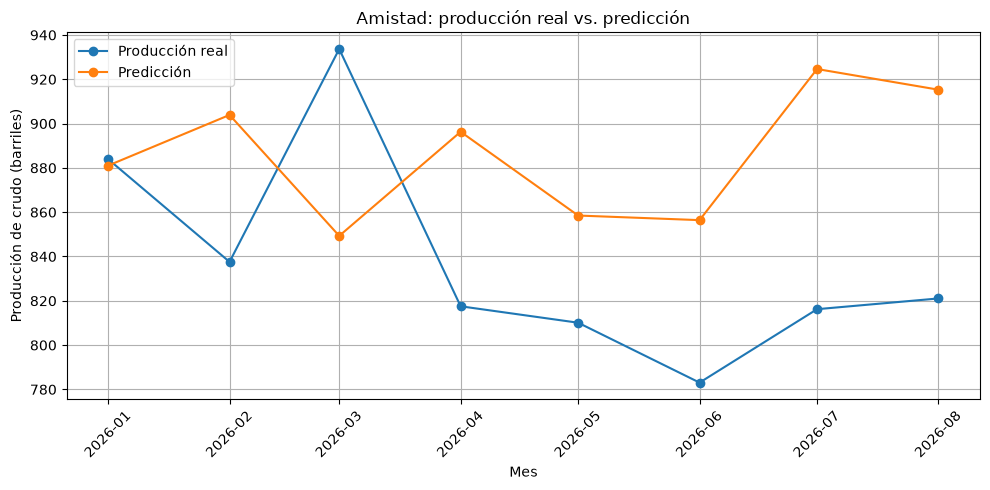

In [43]:
comparacion = pd.DataFrame({"fecha": df_amistad.loc[~train_mask, "fecha_completa"],"real": y_test.values,"prediccion": y_pred})

plt.figure(figsize=(10, 5))
plt.plot(comparacion["fecha"],comparacion["real"],marker="o",label="Producción real")

plt.plot(comparacion["fecha"],comparacion["prediccion"],marker="o",label="Predicción")

plt.title("Amistad: producción real vs. predicción")
plt.xlabel("Mes")
plt.ylabel("Producción de crudo (barriles)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
# 1. Entrenar nuevamente con todos los datos disponibles hasta agosto 2026

df_entrenamiento = df_amistad.copy()

X_final = df_entrenamiento[["crudo_lag_1", "crudo_lag_2", "crudo_lag_3"]]

y_final = df_entrenamiento["produccion_crudo"]
modelo_final = RandomForestRegressor(n_estimators=200,random_state=42)
modelo_final.fit(X_final, y_final)
# 2. Generar predicciones para septiembre-diciembre 2026
ultimos_valores = list(df_entrenamiento["produccion_crudo"].tail(3))

fechas_futuras = pd.date_range(start="2026-09-01",end="2026-12-01",freq="MS")

predicciones = []
for fecha in fechas_futuras:

    X_futuro = pd.DataFrame({"crudo_lag_1": [ultimos_valores[-1]],"crudo_lag_2": [ultimos_valores[-2]],"crudo_lag_3": [ultimos_valores[-3]]})
    pred = modelo_final.predict(X_futuro)[0]
    predicciones.append(pred)
    # La predicción pasa a ser el lag del siguiente mes
    ultimos_valores.append(pred)
# 3. Crear tabla de predicciones
df_predicciones = pd.DataFrame({"fecha": fechas_futuras, "prediccion": predicciones})
print(df_predicciones)

       fecha  prediccion
0 2026-09-01  824.782450
1 2026-10-01  826.078850
2 2026-11-01  838.222675
3 2026-12-01  846.086800


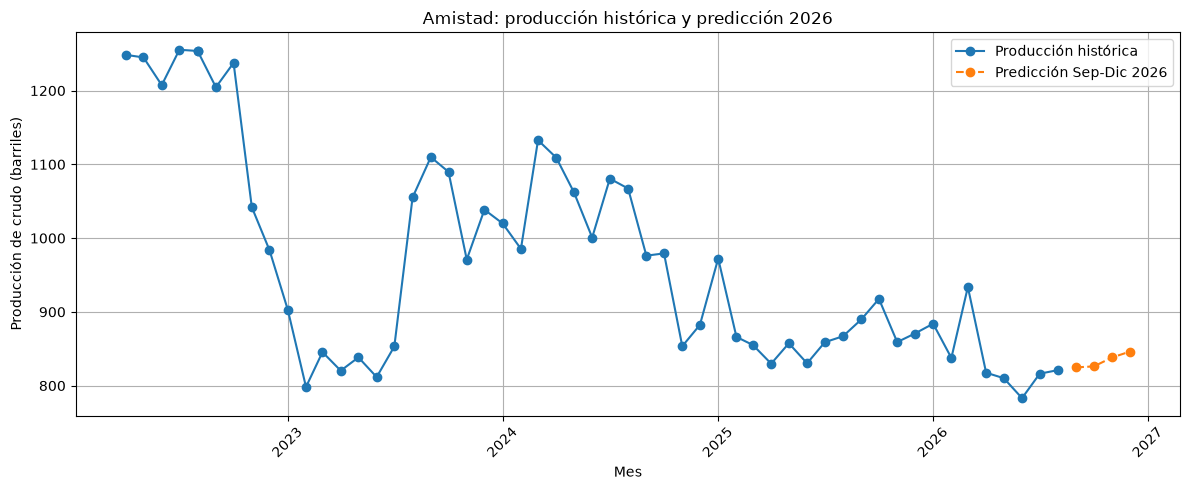

,fecha,prediccion
0,2026-09-01,824.782450
1,2026-10-01,826.078850
2,2026-11-01,838.222675
3,2026-12-01,846.086800


In [47]:
historico = df_amistad[df_amistad["fecha_completa"] <= "2026-08-01"]

plt.figure(figsize=(12, 5))

plt.plot(historico["fecha_completa"],historico["produccion_crudo"],marker="o",label="Producción histórica")

plt.plot(df_predicciones["fecha"],df_predicciones["prediccion"],marker="o",linestyle="--",label="Predicción Sep-Dic 2026")

plt.title("Amistad: producción histórica y predicción 2026")
plt.xlabel("Mes")
plt.ylabel("Producción de crudo (barriles)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
df_predicciones.head()

# Informe

## 1. Contexto
Este análisis se inicia con los datos obtenidos de la producción de hidrocarburos referentes a los campos que maneja la empresa pública Petroecuador, para poder tratar los datos se recurrió a un segundo conjunto de datos para poder vincular la nomenclatura de los campos con su respectivo nombre y con el precio mensual de venta registrado, posteriormente se realizó una limpieza de datos, la normalización, se concluye que quedan 757 registros a tratar referentes a 8 variables respectivamente.

Como parte del análisis exploratorio se estudió la relación entre la producción de crudo y la producción de gas. La correlación de Pearson fue 0.44 y la de Spearman 0.30, lo que indica una asociación positiva, aunque la magnitud difiere según la medida utilizada.

Para la etapa predictiva se seleccionó el activo el campo de produccion AMISTAD y se planteó estimar su producción mensual de crudo utilizando únicamente información histórica de la propia producción.

## 2. Método

Se construyeron tres variables que representan el histórico de producción:

- `crudo_lag_1`: producción de 1 mes atras.
- `crudo_lag_2`: producción de 2 meses atrás.
- `crudo_lag_3`: producción de 3 meses atrás.

La variable objetivo fue `produccion_crudo`.

La separación entre entrenamiento y prueba se realizó temporalmente, utilizando los registros anteriores a enero de 2026 para entrenamiento y los registros desde enero de 2026 para prueba. Después de crear los 3 meses de histórico de producción se obtuvieron:

- **46 observaciones de entrenamiento*.
- **8 observaciones de prueba*.
- **3 variables predictoras*.

El modelo utilizado fue un `RandomForestRegressor` de scikit-learn, con **200 árboles** y `random_state=42`.

Las métricas utilizadas fueron:

- **MAE (Error Absoluto Medio):** mide el error promedio absoluto de las predicciones en las mismas unidades de producción.
- **RMSE (Raíz del Error Cuadrático Medio):** penaliza más los errores grandes.
- **R²:** indica qué tan bien explica el modelo la variabilidad de la variable objetivo en el conjunto evaluado.

## 3. Resultados

En el conjunto de prueba se obtuvieron los siguientes resultados:

El **MAE de 69.60** indica que, en promedio, la diferencia absoluta entre la producción observada y la predicha fue de aproximadamente 69.6 unidades de producción.

El **RMSE de 75.91** es superior al MAE, lo que indica que algunos errores de predicción son mayores que el error absoluto promedio.

El **R² de -1.838** muestra un desempeño débil en el conjunto de prueba: con esta configuración, el modelo no consigue explicar adecuadamente la variabilidad observada en los datos de prueba. Por esta razón, estos resultados deben interpretarse como una evaluación inicial de un modelo simple y no como evidencia de capacidad predictiva robusta.

Posteriormente, se genera predicciones para **septiembre a diciembre de 2026**, utilizando la información histórica disponible hasta agosto de 2026. Las predicciones obtenidas fueron:

| Fecha | Predicción |
|---|---:|
| 2026-09-01 | 824.78 |
| 2026-10-01 | 826.08 |
| 2026-11-01 | 838.22 |
| 2026-12-01 | 846.09 |

Estas predicciones representan una extrapolación del modelo y deben considerarse con cautela debido al desempeño observado en la evaluación temporal.

## 4. Limitaciones

1. **Tamaño reducido de la muestra para el modelo:** después de seleccionar el activo Amistad y crear los históricos de producción, solamente se utilizaron 54 observaciones, de las cuales 46 corresponden a entrenamiento y 8 a prueba.
2. **Un solo activo:** el modelo se construyó únicamente para Amistad, por lo que sus resultados no se pueden generalizar directamente a los demás activos.
3. **Sin ajuste de hiperparámetros:** se utilizó una configuración inicial de Random Forest (`n_estimators=200`, `random_state=42`) sin una búsqueda sistemática de hiperparámetros.
4. **Evaluación temporal corta:** el conjunto de prueba contiene solamente ocho observaciones, por lo que las métricas pueden ser sensibles a los valores particulares de esos meses.
5. **R² negativo:** el valor obtenido en prueba (`-1.838`) indica que el modelo presenta un desempeño insuficiente para explicar la variabilidad del conjunto de prueba bajo esta configuración.
6. **No implica causalidad:** las relaciones observadas entre variables no permiten concluir por sí solas que una variable cause cambios en otra.

## Conclusión

los resultados obtenidos permite establecer una línea base para la predicción de producción de crudo del activo Amistad. Sin embargo, los resultados de evaluación muestran que esta primera configuración necesita mejoras antes de utilizarse para predicciones con mayor confianza.

Como siguientes pasos se podría comparar este modelo con una regresión lineal u otros modelos, incorporar variables adicionales disponibles en el conjunto de datos, ajustar hiperparámetros y utilizar una validación temporal más amplia.